# Part 2: Reply routing decision model

Fine-tunes `LiquidAI/LFM3-1.7B` with Unsloth's Clef decision head on the repository's synthetic reply dataset. Companion to the tutorial on raoofaltaher.com.

In [1]:
import os
import time
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

HF_USERNAME = "raoofaltaher"
PUBLISH = True
LOAD_IN_4BIT = True
TIMINGS = {}

print("Working directory:", Path.cwd())

Working directory: /home/dev/work/lead-decision-models


## Environment

In [2]:
import platform
import torch

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA runtime:", torch.version.cuda)
else:
    raise RuntimeError("A supported GPU runtime is required for this training run.")

Python: 3.13.18
PyTorch: 2.14.1+cu132
CUDA available: True
GPU: NVIDIA GeForce RTX 5090 Laptop GPU
CUDA runtime: 13.2


In [3]:
import json
from collections import Counter

import numpy as np
import pandas as pd
from datasets import Dataset
from sklearn.model_selection import StratifiedGroupKFold
from unsloth import DecisionTrainer, FastDecisionModel, is_bfloat16_supported
from transformers import TrainingArguments

MODEL_ID = "LiquidAI/LFM3-1.7B"
MODEL_REVISION = "ac2586a34f1a1c03329dbdcdefabd8b6478ddaa7"
print("Model:", MODEL_ID, "pinned revision:", MODEL_REVISION)


def to_decision_dataset(frame, builder):
    rows = [
        builder(row)
        for row in frame.to_dict(orient="records")
    ]
    return Dataset.from_list(rows)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1103 19:31:52.555000 4422 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


W1103 19:31:52.579000 4422 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


/home/dev/work/lead-decision-models/unsloth_env/lib/python3.13/site-packages/transformers/configuration_utils.py:723: FutureWarning: `rope_scaling` is deprecated and will be removed in a future version. Set `rope_parameters` instead, with `rope_type` and `rope_theta` included.
  warnings.warn(


🦥 Unsloth Zoo will now patch everything to make training faster!


Model: LiquidAI/LFM3-1.7B pinned revision: ac2586a34f1a1c03329dbdcdefabd8b6478ddaa7


## Reply dataset

In [4]:
REPLY_INTENTS = [
    "interested",
    "meeting_requested",
    "more_information",
    "referral",
    "not_now",
    "objection",
    "wrong_person",
    "out_of_office",
    "not_interested",
    "opt_out",
    "ambiguous",
]

reply_df = pd.read_csv("data/replies/reply_examples.csv")

required_reply_columns = {
    "reply_id",
    "scenario_group",
    "outreach_context",
    "reply_text",
    "reply_intent",
    "is_synthetic",
}

missing_reply_columns = required_reply_columns - set(reply_df.columns)
if missing_reply_columns:
    raise ValueError(f"Missing reply columns: {sorted(missing_reply_columns)}")

reply_df["is_synthetic"] = (
    reply_df["is_synthetic"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
)

reply_df["reply_intent"] = (
    reply_df["reply_intent"]
    .astype(str)
    .str.strip()
)

if not reply_df["is_synthetic"].all():
    raise ValueError("This experiment accepts only explicitly synthetic reply rows.")

if reply_df["reply_id"].duplicated().any():
    raise ValueError("reply_id values must be unique.")

normalized_reply_text = (
    reply_df["reply_text"]
    .astype(str)
    .str.strip()
    .str.casefold()
)

if normalized_reply_text.duplicated().any():
    raise ValueError(
        "Exact duplicate reply text exists. Deduplicate or review it before splitting."
    )

required_text_columns = [
    "reply_id",
    "scenario_group",
    "outreach_context",
    "reply_text",
]

if reply_df[required_text_columns].isna().any().any():
    raise ValueError("Reply IDs, groups, context and text cannot be null.")

if (
    reply_df[required_text_columns]
    .astype(str)
    .apply(lambda column: column.str.strip().eq("").any())
    .any()
):
    raise ValueError("Reply IDs, groups, context and text cannot be blank.")

if not set(reply_df["reply_intent"]).issubset(set(REPLY_INTENTS)):
    raise ValueError("The dataset contains an unknown reply_intent.")

if reply_df.groupby("scenario_group")["reply_intent"].nunique().gt(1).any():
    raise ValueError("A scenario_group cannot contain multiple reply_intent labels.")

if len(reply_df) < 500:
    raise ValueError("The reply dataset must hold at least 500 rows.")

class_counts = reply_df["reply_intent"].value_counts()
print(class_counts)

missing_classes = set(REPLY_INTENTS) - set(class_counts.index)
if missing_classes:
    raise ValueError(f"Missing reply classes: {sorted(missing_classes)}")

if class_counts.min() < 20:
    raise ValueError("Add more examples to the under-represented classes.")

group_counts = reply_df.groupby("reply_intent")["scenario_group"].nunique()
if group_counts.min() < 10:
    raise ValueError(
        "Each reply intent needs at least ten independent scenario groups "
        "for the five-fold grouped split."
    )

from hashlib import sha256
from pathlib import Path

reply_dataset_hash = sha256(
    Path("data/replies/reply_examples.csv").read_bytes()
).hexdigest()
published_hash = Path("data/replies/reply_examples.sha256").read_text(encoding="utf-8").split()[0]

if reply_dataset_hash != published_hash:
    raise ValueError("reply_examples.csv does not match its published SHA-256.")

print("Reply dataset SHA-256 verified:", reply_dataset_hash)

reply_intent
interested           61
referral             61
objection            61
wrong_person         61
ambiguous            60
not_interested       56
more_information     53
meeting_requested    51
not_now              51
out_of_office        51
opt_out              51
Name: count, dtype: int64
Reply dataset SHA-256 verified: c57a26d99d05b29b3ce63c5e627d2a79dd03ed78d3bd35ce1afb1f07fca72439


## Decision records and grouped splits

In [5]:
REPLY_QUESTIONS = {
    "reply_intent": {
        "type": "choice",
        "instructions": (
            "Classify the recipient's reply using the defined intent taxonomy. "
            "Do not infer interest that the recipient did not express."
        ),
        "criteria": {
            "interested": "The recipient expresses interest without requesting a meeting.",
            "meeting_requested": "The recipient asks to schedule or discuss a meeting.",
            "more_information": "The recipient requests details, pricing or documentation.",
            "referral": "The recipient points to another relevant person.",
            "not_now": "The recipient asks to revisit the topic later.",
            "objection": "The recipient raises a concern or reason not to proceed.",
            "wrong_person": "The recipient says they are not responsible for this topic.",
            "out_of_office": "The recipient indicates an absence or return date.",
            "not_interested": "The recipient declines further engagement.",
            "opt_out": "The recipient asks to stop marketing or unsubscribe.",
            "ambiguous": "The reply does not support a reliable intent classification.",
        },
    },
    "follow_up_recommended": {
        "type": "noul",
        "instructions": (
            "Does this reply call for an appropriate next step? "
            "A next step may be a handoff, requested information, a pause "
            "or human review. It does not mean an automatic marketing email."
        ),
    },
}

NO_FOLLOW_UP_INTENTS = {
    "not_interested",
    "opt_out",
}

def make_reply_record(row):
    intent = row["reply_intent"]

    state = {
        "task": "B2B sales reply assessment",
        "outreach_context": row["outreach_context"],
        "recipient_reply": row["reply_text"],
    }

    return {
        "state": json.dumps(state, sort_keys=True, ensure_ascii=False),
        "questions": REPLY_QUESTIONS,
        "gold": {
            "reply_intent": intent,
            "follow_up_recommended": intent not in NO_FOLLOW_UP_INTENTS,
        },
    }

In [6]:
reply_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=3407,
)

reply_folds = list(
    reply_splitter.split(
        reply_df,
        y=reply_df["reply_intent"],
        groups=reply_df["scenario_group"],
    )
)

reply_test_indices = reply_folds[0][1]
reply_validation_indices = reply_folds[1][1]
reply_train_indices = np.concatenate(
    [reply_folds[2][1], reply_folds[3][1], reply_folds[4][1]]
)

reply_train_df = reply_df.iloc[reply_train_indices].reset_index(drop=True)
reply_validation_df = reply_df.iloc[reply_validation_indices].reset_index(drop=True)
reply_test_df = reply_df.iloc[reply_test_indices].reset_index(drop=True)

def scenario_groups(frame):
    return set(frame["scenario_group"])

assert scenario_groups(reply_train_df).isdisjoint(scenario_groups(reply_validation_df))
assert scenario_groups(reply_train_df).isdisjoint(scenario_groups(reply_test_df))
assert scenario_groups(reply_validation_df).isdisjoint(scenario_groups(reply_test_df))

for name, frame in [
    ("train", reply_train_df),
    ("validation", reply_validation_df),
    ("test", reply_test_df),
]:
    missing = set(REPLY_INTENTS) - set(frame["reply_intent"].unique())
    if missing:
        raise ValueError(
            f"{name} split is missing reply classes: {sorted(missing)}. "
            "Add independent scenario groups or revise the split."
        )

    print(name, len(frame))
    print(frame["reply_intent"].value_counts())

train 369
reply_intent
wrong_person         37
interested           36
referral             36
objection            36
ambiguous            36
not_interested       34
more_information     33
opt_out              31
meeting_requested    30
not_now              30
out_of_office        30
Name: count, dtype: int64
validation 124
reply_intent
objection            13
interested           12
referral             12
wrong_person         12
ambiguous            12
not_now              11
out_of_office        11
not_interested       11
meeting_requested    10
more_information     10
opt_out              10
Name: count, dtype: int64
test 124
reply_intent
interested           13
referral             13
objection            12
wrong_person         12
ambiguous            12
meeting_requested    11
not_interested       11
more_information     10
not_now              10
out_of_office        10
opt_out              10
Name: count, dtype: int64


In [7]:
reply_calibration_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=3408,
)

reply_fit_indices, reply_calibration_indices = next(
    reply_calibration_splitter.split(
        reply_train_df,
        y=reply_train_df["reply_intent"],
        groups=reply_train_df["scenario_group"],
    )
)

reply_fit_df = reply_train_df.iloc[reply_fit_indices].reset_index(drop=True)
reply_calibration_df = reply_train_df.iloc[reply_calibration_indices].reset_index(drop=True)

assert scenario_groups(reply_fit_df).isdisjoint(
    scenario_groups(reply_calibration_df)
)

# The approximate overall proportions are 48% fit, 12% calibration,
# 20% validation and 20% test; grouped row counts will vary.

for name, frame in [
    ("optimizer training", reply_fit_df),
    ("calibration", reply_calibration_df),
]:
    missing = set(REPLY_INTENTS) - set(frame["reply_intent"].unique())
    if missing:
        raise ValueError(
            f"{name} split is missing reply classes: {sorted(missing)}. "
            "Add independent scenario groups or revise the split."
        )

    print(name, len(frame))

optimizer training 296
calibration 73


## Text baseline and model

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.pipeline import Pipeline

reply_text_baseline = Pipeline(
    steps=[
        (
            "tfidf",
            TfidfVectorizer(
                ngram_range=(1, 2),
                min_df=2,
                max_features=50000,
                sublinear_tf=True,
            ),
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
            ),
        ),
    ]
)

In [9]:
def new_reply_model(lora_rank=16):
    decision_model, decision_tokenizer = FastDecisionModel.from_pretrained(
        model_name=MODEL_ID,
        revision=MODEL_REVISION,
        trust_remote_code=True,
        max_seq_length=2048,
        load_in_4bit=LOAD_IN_4BIT,
    )

    decision_model = FastDecisionModel.get_peft_model(
        decision_model,
        r=lora_rank,
        lora_alpha=lora_rank,
        lora_dropout=0.0,
        use_gradient_checkpointing="unsloth",
        random_state=3407,
    )
    return decision_model, decision_tokenizer


reply_model, reply_tokenizer = new_reply_model()

reply_train_raw = to_decision_dataset(reply_fit_df, make_reply_record)
reply_calibration_raw = to_decision_dataset(reply_calibration_df, make_reply_record)
reply_validation_raw = to_decision_dataset(reply_validation_df, make_reply_record)
reply_test_raw = to_decision_dataset(reply_test_df, make_reply_record)

reply_train_items_all, reply_train_report = FastDecisionModel.build_dataset(
    reply_train_raw,
    reply_tokenizer,
    reply_model,
)

reply_calibration_items, reply_calibration_report = FastDecisionModel.build_dataset(
    reply_calibration_raw,
    reply_tokenizer,
    reply_model,
)

reply_validation_items, reply_validation_report = FastDecisionModel.build_dataset(
    reply_validation_raw,
    reply_tokenizer,
    reply_model,
)

reply_test_items, reply_test_report = FastDecisionModel.build_dataset(
    reply_test_raw,
    reply_tokenizer,
    reply_model,
)

for name, report in [
    ("train", reply_train_report),
    ("calibration", reply_calibration_report),
    ("validation", reply_validation_report),
    ("test", reply_test_report),
]:
    print(name, report)
    if report["skipped"]:
        raise ValueError(
            f"{name} reply dataset contains skipped decisions: {report['reason']}"
        )

Unsloth: WARNING `trust_remote_code` is True.
Are you certain you want to do remote code execution?
==((====))==  Unsloth 2026.10.11: Fast Lfm3 patching. Transformers: 5.22.1.
   \\   /|    NVIDIA GeForce RTX 5090 Laptop GPU. Num GPUs = 1. Max memory: 23.863 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu132. CUDA: 12.0. CUDA Toolkit: 13.2. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/286 [00:00<?, ?it/s]

Unsloth: Repaired remote modeling code so it trains: Lfm3ForCausalLM.forward.


Unsloth: compiling each transformer block as one region (Lfm3DecoderLayer).


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

train {'total': 592, 'skipped': 0, 'reason': None, 'truncated': 0}
calibration {'total': 146, 'skipped': 0, 'reason': None, 'truncated': 0}
validation {'total': 248, 'skipped': 0, 'reason': None, 'truncated': 0}
test {'total': 248, 'skipped': 0, 'reason': None, 'truncated': 0}


In [10]:
reply_train_items = reply_train_items_all

print("Reply optimizer-training rows:", len(reply_train_items))
print("Reply calibration rows:", len(reply_calibration_items))

reply_calibration_counts = Counter(
    question_type
    for item in reply_calibration_items
    for question_type in item["qtypes"]
)

if (
    len(reply_calibration_counts) != len(REPLY_QUESTIONS)
    or min(reply_calibration_counts.values()) < 10
):
    raise ValueError(
        "Provide at least ten calibration decisions for both reply question types. "
        f"Observed counts: {dict(reply_calibration_counts)}"
    )

# Fit the classical baseline on exactly the same scenario groups as Unsloth.
reply_text_baseline.fit(
    reply_fit_df["reply_text"],
    reply_fit_df["reply_intent"],
)

reply_validation_text_predictions = reply_text_baseline.predict(
    reply_validation_df["reply_text"]
)

print(
    classification_report(
        reply_validation_df["reply_intent"],
        reply_validation_text_predictions,
        labels=REPLY_INTENTS,
        zero_division=0,
    )
)

print(
    "TF-IDF validation macro-F1:",
    f1_score(
        reply_validation_df["reply_intent"],
        reply_validation_text_predictions,
        labels=REPLY_INTENTS,
        average="macro",
        zero_division=0,
    ),
)

reply_baseline = FastDecisionModel.evaluate(
    reply_model,
    reply_tokenizer,
    reply_validation_items,
)

print("Unfine-tuned reply baseline:", reply_baseline)

Reply optimizer-training rows: 296
Reply calibration rows: 73
                   precision    recall  f1-score   support

       interested       0.62      0.42      0.50        12
meeting_requested       1.00      0.40      0.57        10
 more_information       0.56      0.50      0.53        10
         referral       0.56      0.83      0.67        12
          not_now       0.55      1.00      0.71        11
        objection       0.40      0.62      0.48        13
     wrong_person       0.40      0.33      0.36        12
    out_of_office       0.77      0.91      0.83        11
   not_interested       0.42      0.45      0.43        11
          opt_out       1.00      0.40      0.57        10
        ambiguous       0.83      0.42      0.56        12

         accuracy                           0.57       124
        macro avg       0.65      0.57      0.57       124
     weighted avg       0.64      0.57      0.56       124

TF-IDF validation macro-F1: 0.5652430331292474


Unfine-tuned reply baseline: {'accuracy': 0.13306451612903225, 'ece': 0.16774805512038932, 'loss': 1.5470689388532792, 'record_accuracy': 0.0}


## Training

In [11]:
from sklearn.metrics import confusion_matrix, f1_score

def predict_replies(frame, decision_model, decision_tokenizer):
    predictions = []

    for row in frame.to_dict(orient="records"):
        example = make_reply_record(row)

        result = FastDecisionModel.predict(
            decision_model,
            decision_tokenizer,
            example["state"],
            REPLY_QUESTIONS,
        )

        predictions.append(
            {
                "reply_intent": result["reply_intent"]["answer"],
                "reply_intent_confidence": result["reply_intent"]["confidence"],
                "follow_up_recommended": result["follow_up_recommended"]["answer"],
            }
        )

    return pd.DataFrame(predictions)

In [12]:
REPLY_CANDIDATES = [
    {"epochs": 3, "lora_rank": 16},
    {"epochs": 6, "lora_rank": 16},
    {"epochs": 3, "lora_rank": 64},
    {"epochs": 6, "lora_rank": 64},
]

def train_reply_model(num_epochs, lora_rank):
    decision_model, decision_tokenizer = new_reply_model(lora_rank)

    trainer = DecisionTrainer(
        model=decision_model,
        processing_class=decision_tokenizer,
        train_dataset=reply_train_items,
        eval_dataset=reply_validation_items,
        head_learning_rate=1e-4,
        args=TrainingArguments(
            per_device_train_batch_size=8,
            gradient_accumulation_steps=1,
            warmup_steps=10,
            num_train_epochs=num_epochs,
            learning_rate=2e-4,
            lr_scheduler_type="cosine",
            weight_decay=0.01,
            bf16=is_bfloat16_supported(),
            fp16=not is_bfloat16_supported(),
            eval_strategy="epoch",
            logging_steps=5,
            save_strategy="no",
            output_dir=f"outputs/reply-decision-{num_epochs}-epochs-r{lora_rank}",
            report_to="none",
            seed=3407,
        ),
    )

    started = time.perf_counter()
    trainer.train()
    training_seconds = round(time.perf_counter() - started, 1)

    calibration = FastDecisionModel.calibrate(
        decision_model,
        decision_tokenizer,
        reply_calibration_items,
    )

    FastDecisionModel.for_inference(decision_model)
    validation_predictions = predict_replies(reply_validation_df, decision_model, decision_tokenizer)

    return decision_model, decision_tokenizer, {
        "epochs": num_epochs,
        "lora_rank": lora_rank,
        "optimizer_steps": trainer.state.global_step,
        "training_seconds": training_seconds,
        "validation_macro_f1": float(
            f1_score(
                reply_validation_df["reply_intent"],
                validation_predictions["reply_intent"],
                labels=REPLY_INTENTS,
                average="macro",
                zero_division=0,
            )
        ),
        "calibration": calibration,
        "log_history": trainer.state.log_history,
    }

In [13]:
import gc

del reply_model, reply_tokenizer
gc.collect()
torch.cuda.empty_cache()

reply_selection = []
reply_best = None

for settings in REPLY_CANDIDATES:
    candidate = train_reply_model(settings["epochs"], settings["lora_rank"])
    reply_selection.append(candidate[2])
    print(
        f"{settings['epochs']} epochs, LoRA rank {settings['lora_rank']}: "
        f"{candidate[2]['optimizer_steps']} optimizer steps, "
        f"{candidate[2]['training_seconds']} s, "
        f"validation macro-F1 {candidate[2]['validation_macro_f1']:.4f}"
    )
    if reply_best is None or candidate[2]["validation_macro_f1"] > reply_best[2]["validation_macro_f1"]:
        reply_best = candidate
    del candidate
    gc.collect()
    torch.cuda.empty_cache()

reply_model, reply_tokenizer, reply_chosen = reply_best
del reply_best

reply_calibration_metrics = reply_chosen["calibration"]
TIMINGS["reply_training"] = reply_chosen["training_seconds"]
TIMINGS["reply_epoch_selection"] = round(sum(result["training_seconds"] for result in reply_selection), 1)
peak_vram_gb = round(torch.cuda.max_memory_allocated() / 1024**3, 2)

print("Chosen on validation macro-F1:", reply_chosen["epochs"], "epochs, LoRA rank", reply_chosen["lora_rank"])
print("Calibration of the chosen model:", reply_calibration_metrics)
print("Peak VRAM GB:", peak_vram_gb)

Unsloth: WARNING `trust_remote_code` is True.
Are you certain you want to do remote code execution?
==((====))==  Unsloth 2026.10.11: Fast Lfm3 patching. Transformers: 5.22.1.
   \\   /|    NVIDIA GeForce RTX 5090 Laptop GPU. Num GPUs = 1. Max memory: 23.863 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu132. CUDA: 12.0. CUDA Toolkit: 13.2. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/286 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Unsloth: Will smartly offload gradients to save VRAM!


Epoch,Training Loss,Validation Loss
1,0.585467,0.498170
2,0.143252,0.327389
3,0.008304,0.377378


... (16 outputs left out)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Epoch,Training Loss,Validation Loss
1,0.441321,0.437804
2,0.068517,0.411828
3,0.057090,0.624372
4,0.001318,0.127889
5,0.000067,0.129825
6,0.000057,0.126778


6 epochs, LoRA rank 64: 222 optimizer steps, 207.0 s, validation macro-F1 0.9453
Chosen on validation macro-F1: 6 epochs, LoRA rank 64
Calibration of the chosen model: {'accuracy': 0.9657534246575342, 'ece': 0.02417528955903771, 'loss': 0.07532362670451807, 'record_accuracy': 0.9452054794520548, 'fitted_types': [0, 2]}
Peak VRAM GB: 4.6


## Calibration and evaluation

In [14]:
reply_validation_metrics = FastDecisionModel.evaluate(
    reply_model,
    reply_tokenizer,
    reply_validation_items,
)

print(reply_validation_metrics)

{'accuracy': 0.967741935483871, 'ece': 0.019779227553836796, 'loss': 0.10463338459266519, 'record_accuracy': 0.9354838709677419}


In [15]:
_predict_start = time.perf_counter()

In [16]:
FastDecisionModel.for_inference(reply_model)

reply_validation_predictions = predict_replies(
    reply_validation_df,
    reply_model,
    reply_tokenizer,
)

print(
    classification_report(
        reply_validation_df["reply_intent"],
        reply_validation_predictions["reply_intent"],
        labels=REPLY_INTENTS,
        zero_division=0,
    )
)

validation_follow_up_labels = reply_validation_df["reply_intent"].map(
    lambda intent: intent not in NO_FOLLOW_UP_INTENTS
)

print(
    "Follow-up decision metrics:",
    classification_report(
        validation_follow_up_labels,
        reply_validation_predictions["follow_up_recommended"],
        labels=[False, True],
        zero_division=0,
    ),
)

print(
    "Macro-F1:",
    f1_score(
        reply_validation_df["reply_intent"],
        reply_validation_predictions["reply_intent"],
        labels=REPLY_INTENTS,
        average="macro",
        zero_division=0,
    ),
)

print(
    confusion_matrix(
        reply_validation_df["reply_intent"],
        reply_validation_predictions["reply_intent"],
        labels=REPLY_INTENTS,
    )
)

                   precision    recall  f1-score   support

       interested       0.91      0.83      0.87        12
meeting_requested       1.00      1.00      1.00        10
 more_information       1.00      0.90      0.95        10
         referral       0.92      1.00      0.96        12
          not_now       0.91      0.91      0.91        11
        objection       1.00      1.00      1.00        13
     wrong_person       1.00      0.83      0.91        12
    out_of_office       0.92      1.00      0.96        11
   not_interested       1.00      1.00      1.00        11
          opt_out       1.00      1.00      1.00        10
        ambiguous       0.79      0.92      0.85        12

         accuracy                           0.94       124
        macro avg       0.95      0.94      0.95       124
     weighted avg       0.95      0.94      0.94       124

Follow-up decision metrics:               precision    recall  f1-score   support

       False       1.00      

In [17]:
mean_predict_ms = round((time.perf_counter() - _predict_start) * 1000 / len(reply_validation_df), 1)
print("Mean milliseconds per reply prediction:", mean_predict_ms)

Mean milliseconds per reply prediction: 75.6


In [18]:
reply_test_metrics = FastDecisionModel.evaluate(
    reply_model,
    reply_tokenizer,
    reply_test_items,
)

FastDecisionModel.for_inference(reply_model)

reply_test_predictions = predict_replies(
    reply_test_df,
    reply_model,
    reply_tokenizer,
)

print("Unsloth reply test metrics:", reply_test_metrics)

print(
    classification_report(
        reply_test_df["reply_intent"],
        reply_test_predictions["reply_intent"],
        labels=REPLY_INTENTS,
        zero_division=0,
    )
)

reply_test_text_predictions = reply_text_baseline.predict(
    reply_test_df["reply_text"]
)

print(
    "TF-IDF test macro-F1:",
    f1_score(
        reply_test_df["reply_intent"],
        reply_test_text_predictions,
        labels=REPLY_INTENTS,
        average="macro",
        zero_division=0,
    ),
)

print(
    classification_report(
        reply_test_df["reply_intent"],
        reply_test_text_predictions,
        labels=REPLY_INTENTS,
        zero_division=0,
    )
)

test_follow_up_labels = reply_test_df["reply_intent"].map(
    lambda intent: intent not in NO_FOLLOW_UP_INTENTS
)

print(
    "Follow-up test metrics:",
    classification_report(
        test_follow_up_labels,
        reply_test_predictions["follow_up_recommended"],
        labels=[False, True],
        zero_division=0,
    ),
)

print(
    "Test macro-F1:",
    f1_score(
        reply_test_df["reply_intent"],
        reply_test_predictions["reply_intent"],
        labels=REPLY_INTENTS,
        average="macro",
        zero_division=0,
    ),
)

Unsloth reply test metrics: {'accuracy': 0.9758064516129032, 'ece': 0.01909714937210081, 'loss': 0.09047679677076949, 'record_accuracy': 0.9596774193548387}
                   precision    recall  f1-score   support

       interested       1.00      1.00      1.00        13
meeting_requested       1.00      1.00      1.00        11
 more_information       1.00      1.00      1.00        10
         referral       1.00      1.00      1.00        13
          not_now       0.90      0.90      0.90        10
        objection       1.00      1.00      1.00        12
     wrong_person       1.00      1.00      1.00        12
    out_of_office       1.00      1.00      1.00        10
   not_interested       0.85      1.00      0.92        11
          opt_out       1.00      0.90      0.95        10
        ambiguous       1.00      0.92      0.96        12

         accuracy                           0.98       124
        macro avg       0.98      0.97      0.97       124
     weighted a

## Plots

In [19]:
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
FIGURES = Path("outputs/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
        "legend.labelcolor": INK_SECONDARY,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)


def save_figure(figure, name):
    path = FIGURES / f"{name}.png"
    figure.savefig(path, dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.close(figure)
    display(Image(filename=str(path)))
    print("Saved", path)

from sklearn.calibration import calibration_curve

[matplotlib.font_manager|WARNING]findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


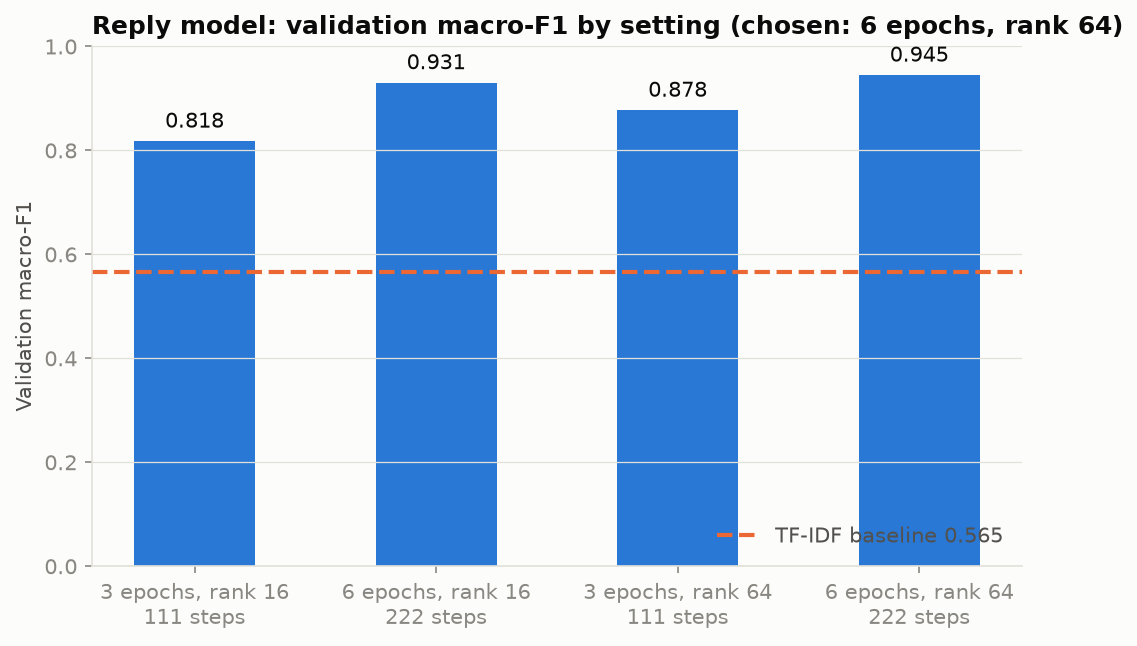

Saved outputs/figures/reply-epoch-choice.png


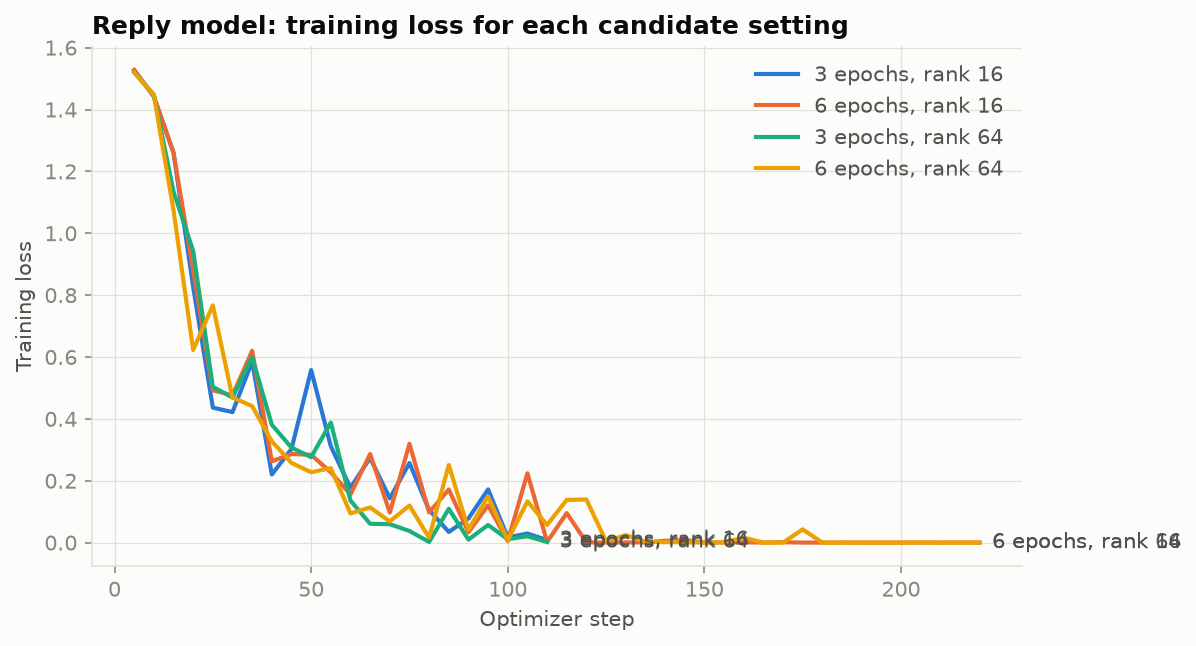

Saved outputs/figures/reply-training-loss.png


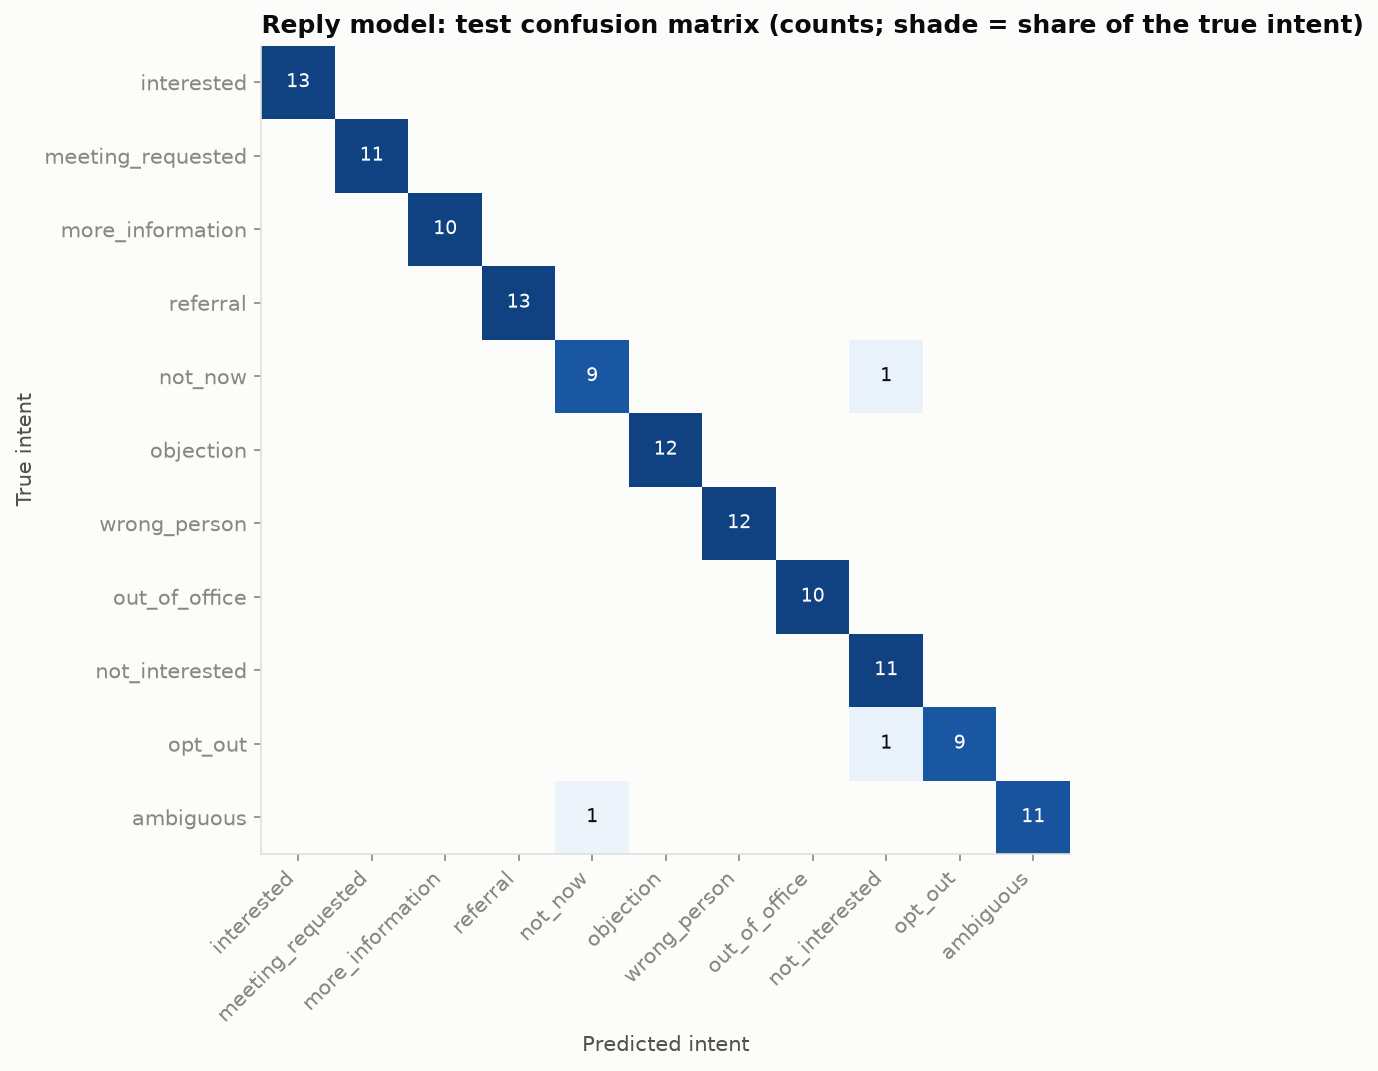

Saved outputs/figures/reply-confusion-matrix.png


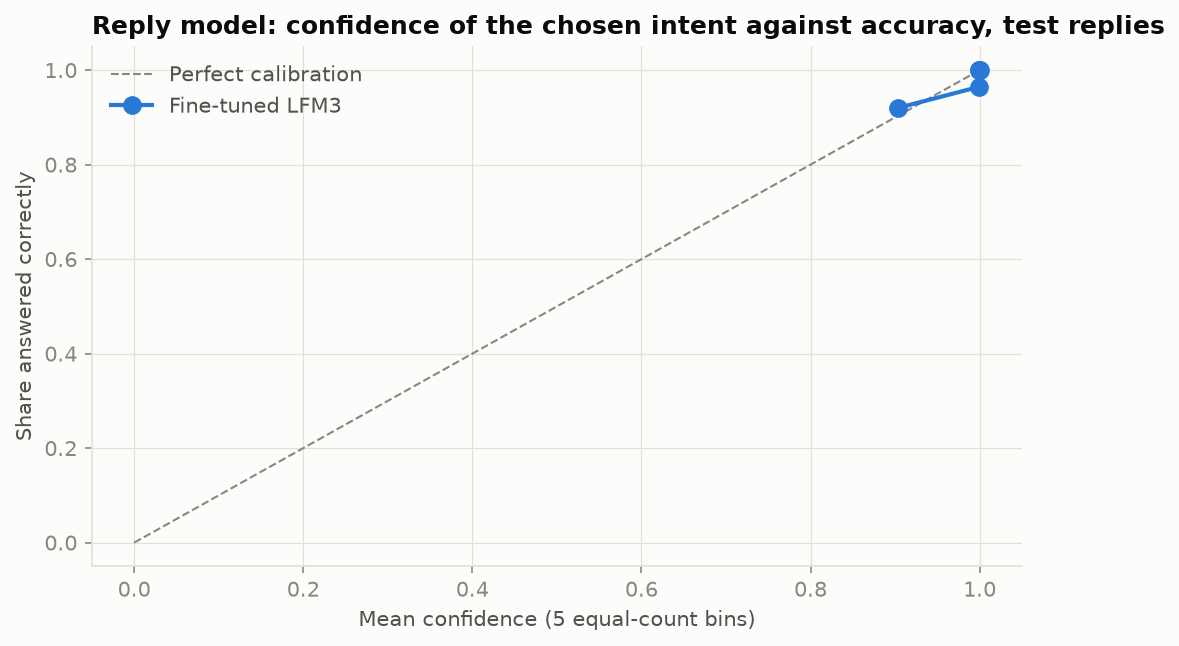

Saved outputs/figures/reply-calibration.png


In [20]:
reply_test_df[["reply_id", "reply_intent"]].reset_index(drop=True).assign(
    predicted_intent=reply_test_predictions["reply_intent"],
    confidence=reply_test_predictions["reply_intent_confidence"],
    tfidf_intent=reply_test_text_predictions,
).to_csv("outputs/reply-test-predictions.csv", index=False)

tfidf_validation_macro_f1 = f1_score(
    reply_validation_df["reply_intent"],
    reply_validation_text_predictions,
    labels=REPLY_INTENTS,
    average="macro",
    zero_division=0,
)
figure, axis = plt.subplots(figsize=(8, 4.5))
positions = range(len(reply_selection))
values = [result["validation_macro_f1"] for result in reply_selection]
bars = axis.bar(positions, values, width=0.5, color=SERIES[0])
axis.bar_label(bars, labels=[f"{value:.3f}" for value in values], padding=4, color=INK)
axis.axhline(tfidf_validation_macro_f1, color=SERIES[1], linewidth=2, linestyle="--", label=f"TF-IDF baseline {tfidf_validation_macro_f1:.3f}")
axis.set_xticks(
    list(positions),
    [f"{result['epochs']} epochs, rank {result['lora_rank']}\n{result['optimizer_steps']} steps" for result in reply_selection],
)
axis.set_ylim(0, 1)
axis.set_title(
    f"Reply model: validation macro-F1 by setting (chosen: {reply_chosen['epochs']} epochs, rank {reply_chosen['lora_rank']})"
)
axis.set_ylabel("Validation macro-F1")
axis.legend(loc="lower right")
axis.grid(axis="x", visible=False)
save_figure(figure, "reply-epoch-choice")

figure, axis = plt.subplots(figsize=(8, 4.5))
for result, color in zip(reply_selection, SERIES):
    points = [(entry["step"], entry["loss"]) for entry in result["log_history"] if "loss" in entry]
    label = f"{result['epochs']} epochs, rank {result['lora_rank']}"
    axis.plot(*zip(*points), color=color, label=label)
    axis.annotate(label, points[-1], xytext=(6, 0), textcoords="offset points", va="center", color=INK_SECONDARY)
axis.set_title("Reply model: training loss for each candidate setting")
axis.set_xlabel("Optimizer step")
axis.set_ylabel("Training loss")
axis.legend(loc="upper right")
save_figure(figure, "reply-training-loss")

test_matrix = confusion_matrix(reply_test_df["reply_intent"], reply_test_predictions["reply_intent"], labels=REPLY_INTENTS)
row_share = test_matrix / test_matrix.sum(axis=1, keepdims=True).clip(min=1)
figure, axis = plt.subplots(figsize=(8, 7))
axis.imshow(row_share, cmap=matplotlib.colors.LinearSegmentedColormap.from_list("blue", [SURFACE, "#cde2fb", "#6da7ec", "#2a78d6", "#104281"]), vmin=0, vmax=1)
for true_index in range(len(REPLY_INTENTS)):
    for predicted_index in range(len(REPLY_INTENTS)):
        count = test_matrix[true_index, predicted_index]
        if count:
            axis.text(predicted_index, true_index, count, ha="center", va="center", fontsize=9, color="#ffffff" if row_share[true_index, predicted_index] > 0.5 else INK)
axis.set_xticks(range(len(REPLY_INTENTS)), REPLY_INTENTS, rotation=45, ha="right")
axis.set_yticks(range(len(REPLY_INTENTS)), REPLY_INTENTS)
axis.set_xlabel("Predicted intent")
axis.set_ylabel("True intent")
axis.grid(False)
axis.set_title("Reply model: test confusion matrix (counts; shade = share of the true intent)")
save_figure(figure, "reply-confusion-matrix")

figure, axis = plt.subplots(figsize=(8, 4.5))
correct = (reply_test_predictions["reply_intent"] == reply_test_df["reply_intent"].reset_index(drop=True)).astype(int)
observed, predicted = calibration_curve(correct, reply_test_predictions["reply_intent_confidence"], n_bins=5, strategy="quantile")
axis.plot([0, 1], [0, 1], color=MUTED, linewidth=1, linestyle="--", label="Perfect calibration")
axis.plot(predicted, observed, color=SERIES[0], marker="o", markersize=8, label="Fine-tuned LFM3")
axis.set_title("Reply model: confidence of the chosen intent against accuracy, test replies")
axis.set_xlabel("Mean confidence (5 equal-count bins)")
axis.set_ylabel("Share answered correctly")
axis.legend(loc="upper left")
save_figure(figure, "reply-calibration")

## Routing policy

In [21]:
REPLY_ACTIONS = {
    "interested": "handoff_to_sales",
    "meeting_requested": "handoff_to_sales",
    "more_information": "prepare_requested_information",
    "referral": "review_referral",
    "not_now": "schedule_later_after_date_confirmation",
    "objection": "human_review",
    "wrong_person": "human_review",
    "out_of_office": "pause_until_return_date_confirmation",
    "not_interested": "stop_sequence",
    "opt_out": "suppress_marketing",
    "ambiguous": "human_review",
}

def route_reply(
    predicted_intent,
    model_follow_up_recommended,
    contact_is_suppressed,
    explicit_opt_out_event,
):
    if isinstance(contact_is_suppressed, np.bool_):
        contact_is_suppressed = bool(contact_is_suppressed)
    if isinstance(explicit_opt_out_event, np.bool_):
        explicit_opt_out_event = bool(explicit_opt_out_event)

    if (
        contact_is_suppressed is True
        or explicit_opt_out_event is True
        or predicted_intent == "opt_out"
    ):
        return {
            "action": "suppress_marketing",
            "model_follow_up_recommended": (
                model_follow_up_recommended
                if isinstance(model_follow_up_recommended, (bool, np.bool_))
                else None
            ),
            "policy_follow_up_recommended": False,
            "send": False,
        }

    if (
        contact_is_suppressed is not False
        or explicit_opt_out_event is not False
    ):
        return {
            "action": "verify_suppression_and_opt_out_status",
            "model_follow_up_recommended": None,
            "policy_follow_up_recommended": False,
            "send": False,
        }

    if not isinstance(model_follow_up_recommended, (bool, np.bool_)):
        return {
            "action": "human_review",
            "reason": "invalid_follow_up_model_output",
            "model_follow_up_recommended": None,
            "policy_follow_up_recommended": False,
            "send": False,
        }

    model_follow_up_recommended = bool(model_follow_up_recommended)

    if predicted_intent not in REPLY_ACTIONS:
        return {
            "action": "human_review",
            "reason": "unknown_reply_intent",
            "model_follow_up_recommended": model_follow_up_recommended,
            "policy_follow_up_recommended": False,
            "send": False,
        }

    policy_follow_up_recommended = (
        predicted_intent not in NO_FOLLOW_UP_INTENTS
    )

    if not policy_follow_up_recommended:
        return {
            "action": REPLY_ACTIONS[predicted_intent],
            "model_follow_up_recommended": model_follow_up_recommended,
            "policy_follow_up_recommended": False,
            "send": False,
        }

    if not model_follow_up_recommended:
        return {
            "action": "human_review",
            "reason": "intent_and_follow_up_decisions_disagree",
            "model_follow_up_recommended": False,
            "policy_follow_up_recommended": True,
            "send": False,
        }

    return {
        "action": REPLY_ACTIONS[predicted_intent],
        "model_follow_up_recommended": True,
        "policy_follow_up_recommended": True,
        "send": False,
    }

In [22]:
sample_reply = reply_validation_predictions.iloc[0]

print(
    route_reply(
        predicted_intent=sample_reply["reply_intent"],
        model_follow_up_recommended=sample_reply["follow_up_recommended"],
        contact_is_suppressed=False,
        explicit_opt_out_event=False,
    )
)

{'action': 'schedule_later_after_date_confirmation', 'model_follow_up_recommended': True, 'policy_follow_up_recommended': True, 'send': False}


In [23]:
import numpy as np

assert route_reply(
    predicted_intent="interested",
    model_follow_up_recommended=True,
    contact_is_suppressed=False,
    explicit_opt_out_event=True,
)["action"] == "suppress_marketing"

assert route_reply(
    predicted_intent="interested",
    model_follow_up_recommended=True,
    contact_is_suppressed=None,
    explicit_opt_out_event=False,
)["action"] == "verify_suppression_and_opt_out_status"

assert route_reply(
    predicted_intent="interested",
    model_follow_up_recommended=False,
    contact_is_suppressed=False,
    explicit_opt_out_event=False,
)["action"] == "human_review"

assert route_reply(
    predicted_intent="interested",
    model_follow_up_recommended="False",
    contact_is_suppressed=False,
    explicit_opt_out_event=False,
)["reason"] == "invalid_follow_up_model_output"

assert route_reply(
    predicted_intent="opt_out",
    model_follow_up_recommended="invalid",
    contact_is_suppressed=False,
    explicit_opt_out_event=False,
)["action"] == "suppress_marketing"

assert route_reply(
    predicted_intent="interested",
    model_follow_up_recommended="invalid",
    contact_is_suppressed=np.bool_(True),
    explicit_opt_out_event=np.bool_(False),
)["action"] == "suppress_marketing"

## Save, publish and release

In [24]:
reply_model.save_pretrained("outputs/reply-decision-adapter")
reply_model.save_pretrained_merged(
    "outputs/reply-decision-merged",
    reply_tokenizer,
)

Unsloth: Restored added_tokens_decoder metadata in /home/dev/work/lead-decision-models/outputs/reply-decision-adapter/.unsloth-save-szwgu6us/tokenizer_config.json.


Unsloth: Restored added_tokens_decoder metadata in /home/dev/work/lead-decision-models/outputs/reply-decision-merged/.unsloth-save-6turp0u0/tokenizer_config.json.


/home/dev/work/lead-decision-models/unsloth_env/lib/python3.13/site-packages/unsloth_zoo/saving_utils.py:5436: UserWarning: Unsloth: Could not read the base config from `LiquidAI/LFM3-1.7B` (The repository LiquidAI/LFM3-1.7B contains custom code which must be executed to correctly load the model. You can inspect the repository content at https://hf.co/LiquidAI/LFM3-1.7B .
 You can inspect the repository content at https://hf.co/LiquidAI/LFM3-1.7B.
Please pass the argument `trust_remote_code=True` to allow custom code to be run.). Falling back to the in-memory config, which might not describe the exported weights (see #969).
  warnings.warn(


/home/dev/work/lead-decision-models/unsloth_env/lib/python3.13/site-packages/unsloth_zoo/saving_utils.py:3849: UserWarning: Unsloth: `LiquidAI/LFM3-1.7B` was loaded without a recorded commit, so its repo code was not copied into the export. Copy the repo's *.py files at the revision you loaded into `/home/dev/work/lead-decision-models/outputs/reply-decision-merged/.unsloth-save-6turp0u0` before loading it with trust_remote_code=True.
  warnings.warn(


Found HuggingFace hub cache directory: /home/dev/.cache/huggingface/hub
Checking cache directory for required files...


Unsloth: Copying 1 files from cache to `/home/dev/work/lead-decision-models/outputs/reply-decision-merged/.unsloth-save-6turp0u0`:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Unsloth: Merging weights into 16bit:   0%|          | 0/1 [00:00<?, ?it/s]

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:02<00:00,  2.32s/it]

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:02<00:00,  2.32s/it]

Unsloth: Merge process complete. Saved to `/home/dev/work/lead-decision-models/outputs/reply-decision-merged/.unsloth-save-6turp0u0`


In [25]:
REPLY_REPO = f"{HF_USERNAME}/lead-decision-models-reply-router"

if PUBLISH:
    reply_model.push_to_hub(REPLY_REPO, reply_tokenizer)
    reply_model.push_to_hub_merged(f"{REPLY_REPO}-merged", reply_tokenizer, save_method="merged_16bit")
    print("Published", REPLY_REPO, "and", f"{REPLY_REPO}-merged")

Unsloth: Restored added_tokens_decoder metadata in /tmp/tmpji2i8pci/.unsloth-save-me2z9ili/tokenizer_config.json.


Unsloth: Saved the decision model to https://huggingface.co/raoofaltaher/lead-decision-models-reply-router


Unsloth: Restored added_tokens_decoder metadata in /tmp/tmpect3jfv3/.unsloth-save-ccawdaa8/tokenizer_config.json.


/home/dev/work/lead-decision-models/unsloth_env/lib/python3.13/site-packages/unsloth_zoo/saving_utils.py:3849: UserWarning: Unsloth: `LiquidAI/LFM3-1.7B` was loaded without a recorded commit, so its repo code was not copied into the export. Copy the repo's *.py files at the revision you loaded into `/tmp/tmpect3jfv3/.unsloth-save-ccawdaa8` before loading it with trust_remote_code=True.
  warnings.warn(


Found HuggingFace hub cache directory: /home/dev/.cache/huggingface/hub
Checking cache directory for required files...


Unsloth: Copying 1 files from cache to `/tmp/tmpect3jfv3/.unsloth-save-ccawdaa8`:   0%|          | 0/1 [00:00<?, ?it/s]

... (6 outputs left out)

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:03<00:00,  3.39s/it]

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:03<00:00,  3.40s/it]

Unsloth: Merge process complete. Saved to `/tmp/tmpect3jfv3/.unsloth-save-ccawdaa8`


Unsloth: Saved the decision model to https://huggingface.co/raoofaltaher/lead-decision-models-reply-router-merged
Published raoofaltaher/lead-decision-models-reply-router and raoofaltaher/lead-decision-models-reply-router-merged


In [26]:
import gc

del reply_model, reply_tokenizer
gc.collect()
torch.cuda.empty_cache()

## Reload the merged model

In [27]:
reloaded_reply_model, reloaded_reply_tokenizer = FastDecisionModel.from_pretrained(
    model_name="outputs/reply-decision-merged",
    trust_remote_code=True,
    max_seq_length=2048,
    load_in_4bit=LOAD_IN_4BIT,
)

FastDecisionModel.for_inference(reloaded_reply_model)

reply_example = make_reply_record(reply_test_df.iloc[0])
reply_reload_prediction = FastDecisionModel.predict(
    reloaded_reply_model,
    reloaded_reply_tokenizer,
    reply_example["state"],
    REPLY_QUESTIONS,
)

print(reply_reload_prediction)

reply_before_export = reply_test_predictions.iloc[0]
print(
    "Reply class agreement after export:",
    reply_reload_prediction["reply_intent"]["answer"]
    == reply_before_export["reply_intent"],
    reply_reload_prediction["follow_up_recommended"]["answer"]
    == bool(reply_before_export["follow_up_recommended"]),
)

Unsloth: WARNING `trust_remote_code` is True.
Are you certain you want to do remote code execution?
==((====))==  Unsloth 2026.10.11: Fast Lfm3 patching. Transformers: 5.22.1.
   \\   /|    NVIDIA GeForce RTX 5090 Laptop GPU. Num GPUs = 1. Max memory: 23.863 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu132. CUDA: 12.0. CUDA Toolkit: 13.2. Triton: 3.8.0
\        /    Bfloat16 = TRUE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/286 [00:00<?, ?it/s]

Unsloth: Repaired remote modeling code so it trains: Lfm3ForCausalLM.forward.


Unsloth: compiling each transformer block as one region (Lfm3DecoderLayer).


{'reply_intent': {'type': 'choice', 'choice': 'interested', 'confidence': 0.9996, 'probabilities': {'interested': 0.9996, 'meeting_requested': 0.0, 'more_information': 0.0, 'referral': 0.0, 'not_now': 0.0, 'objection': 0.0, 'wrong_person': 0.0, 'out_of_office': 0.0, 'not_interested': 0.0, 'opt_out': 0.0, 'ambiguous': 0.0002}, 'answer': 'interested'}, 'follow_up_recommended': {'type': 'noul', 'noul': 0.9997, 'answer': True, 'probabilities': {'true': 0.9997, 'false': 0.0003}}}
Reply class agreement after export: True True


## Metrics and experiment manifest

In [28]:
import hashlib
import importlib.metadata
import platform

def installed_version(distribution):
    try:
        return importlib.metadata.version(distribution)
    except importlib.metadata.PackageNotFoundError:
        return None

reply_metrics = {
    "model_id": MODEL_ID,
    "model_revision": MODEL_REVISION,
    "load_in_4bit": LOAD_IN_4BIT,
    "splits": {
        "optimizer_training": len(reply_fit_df),
        "calibration": len(reply_calibration_df),
        "validation": len(reply_validation_df),
        "test": len(reply_test_df),
    },
    "baseline_untrained": reply_baseline,
    "tfidf": {
        "validation_macro_f1": float(f1_score(reply_validation_df["reply_intent"], reply_validation_text_predictions, labels=REPLY_INTENTS, average="macro", zero_division=0)),
        "test_macro_f1": float(f1_score(reply_test_df["reply_intent"], reply_test_text_predictions, labels=REPLY_INTENTS, average="macro", zero_division=0)),
    },
    "epoch_selection": [{key: value for key, value in result.items() if key not in ("calibration", "log_history")} for result in reply_selection],
    "chosen_epochs": reply_chosen["epochs"],
    "calibration": reply_calibration_metrics,
    "validation": {**reply_validation_metrics, "macro_f1": float(f1_score(reply_validation_df["reply_intent"], reply_validation_predictions["reply_intent"], labels=REPLY_INTENTS, average="macro", zero_division=0))},
    "test": {**reply_test_metrics, "macro_f1": float(f1_score(reply_test_df["reply_intent"], reply_test_predictions["reply_intent"], labels=REPLY_INTENTS, average="macro", zero_division=0))},
    "test_report": classification_report(reply_test_df["reply_intent"], reply_test_predictions["reply_intent"], labels=REPLY_INTENTS, output_dict=True, zero_division=0),
    "follow_up_report": classification_report(test_follow_up_labels, reply_test_predictions["follow_up_recommended"], labels=[False, True], output_dict=True, zero_division=0),
    "confusion_matrix": {"labels": REPLY_INTENTS, "matrix": confusion_matrix(reply_test_df["reply_intent"], reply_test_predictions["reply_intent"], labels=REPLY_INTENTS).tolist()},
    "timings_seconds": TIMINGS,
    "peak_vram_gb": peak_vram_gb,
    "mean_predict_ms": mean_predict_ms,
}
Path("outputs/reply-metrics.json").write_text(json.dumps(reply_metrics, indent=2, default=float), encoding="utf-8")

lead_metrics = json.loads(Path("outputs/lead-metrics.json").read_text(encoding="utf-8"))

experiment_manifest = {
    "experiment": "unsloth-b2b-lead-and-reply-decision-models",
    "dataset": {
        "leadforge_commit": lead_metrics["dataset"]["leadforge_commit"],
        "leadforge_release": "v0.1.0-alpha",
        "leadforge_tier": "intermediate",
        "leadforge_task": "converted_within_90_days",
        "lead_target_counts": lead_metrics["dataset"]["target_counts"],
        "reply_dataset": "synthetic-llm-generated-automatically-checked",
        "reply_dataset_sha256": reply_dataset_hash,
        "reply_intent_counts": {key: int(value) for key, value in reply_df["reply_intent"].value_counts().items()},
    },
    "base_model": {"id": MODEL_ID, "revision": MODEL_REVISION, "load_in_4bit": LOAD_IN_4BIT},
    "splits": {"lead": lead_metrics["splits"], "reply": reply_metrics["splits"]},
    "seed": 3407,
    "calibration_split_seed": 3408,
    "training": {
        "learning_rate": 2e-4,
        "head_learning_rate": 1e-4,
        "max_seq_length": 2048,
        "lead": {"epochs": 2, "per_device_train_batch_size": 8, "gradient_accumulation_steps": 4, "lora_rank": 16, "lora_alpha": 16},
        "reply": {"epochs": reply_chosen["epochs"], "per_device_train_batch_size": 8, "gradient_accumulation_steps": 1, "lora_rank": reply_chosen["lora_rank"], "lora_alpha": reply_chosen["lora_rank"]},
    },
    "timings_seconds": {**lead_metrics["timings_seconds"], **TIMINGS},
    "peak_vram_gb": {"lead": lead_metrics["peak_vram_gb"], "reply": peak_vram_gb},
    "runtime": {
        "python": platform.python_version(),
        "pytorch": torch.__version__,
        "cuda_runtime": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0),
        "packages": {
            name: installed_version(name)
            for name in ["unsloth", "unsloth_zoo", "transformers", "bitsandbytes", "datasets", "pandas", "scikit-learn", "huggingface-hub"]
        },
    },
    "policy_versions": {
        "icp_policy": "fictional-procurement-icp-v1",
        "reply_taxonomy": "b2b-reply-intents-v1",
        "outreach_policy": "human-approval-and-external-suppression-v1",
    },
}

Path("outputs/experiment-manifest.json").write_text(json.dumps(experiment_manifest, indent=2, default=float), encoding="utf-8")
print("Wrote outputs/reply-metrics.json and outputs/experiment-manifest.json")

Wrote outputs/reply-metrics.json and outputs/experiment-manifest.json
